# Практическое занятие №3: Свёртка, корреляция и Z-преобразование

## Подготовка окружения

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
from pathlib import Path

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
rng = np.random.default_rng(34)
data_dir = Path('data') if Path('data').is_dir() else Path('../data')

## Задание 1. Свёртка гауссовых функций: сравнение численного и аналитического результатов

### Теоретическое введение
Свёртка двух гауссовых функций даёт гауссову функцию с дисперсией, равной сумме дисперсий. Если
$$
f(t) = \frac{1}{\sqrt{2\pi\sigma_1^2}} e^{-t^2/(2\sigma_1^2)}, \quad g(t) = \frac{1}{\sqrt{2\pi\sigma_2^2}} e^{-t^2/(2\sigma_2^2)},
$$
то
$$
(f * g)(t) = \frac{1}{\sqrt{2\pi(\sigma_1^2+\sigma_2^2)}} e^{-t^2/(2(\sigma_1^2+\sigma_2^2))}.
$$

### Задание
1. Сгенерируйте дискретные гауссовы импульсы (например, с помощью `scipy.signal.windows.gaussian`) с заданными стандартными отклонениями `sigma1=3`, `sigma2=5`. Используйте длину окна, достаточную для захвата всей значимой части (например, 10*sigma).
2. Вычислите свёртку численно с помощью `np.convolve`.
3. Постройте графики:
   - Исходные функции.
   - Результат свёртки (численный).
   - Теоретическую гауссову функцию с дисперсией `sigma1^2 + sigma2^2`.
4. Оцените среднеквадратичную ошибку между численным и теоретическим результатами.

Ошибка: 6.882016917577217e-09


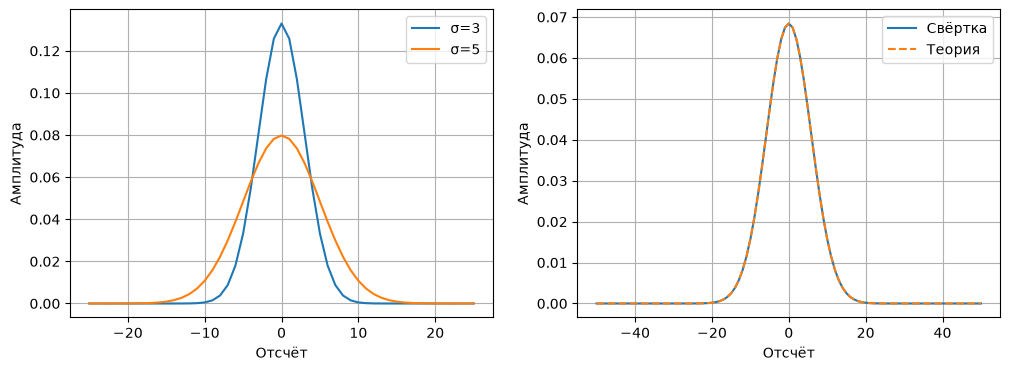

In [2]:
sigma1, sigma2 = 3, 5
n = np.arange(-25, 26)
f = signal.windows.gaussian(len(n), sigma1) / (np.sqrt(2*np.pi)*sigma1)
g = signal.windows.gaussian(len(n), sigma2) / (np.sqrt(2*np.pi)*sigma2)
conv = np.convolve(f, g)
nc = np.arange(-50, 51)
sigma = np.sqrt(sigma1**2 + sigma2**2)
theory = np.exp(-nc**2/(2*sigma**2)) / (np.sqrt(2*np.pi)*sigma)
print('Ошибка:', np.sqrt(np.mean((conv-theory)**2)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(n, f, label='σ=3')
axes[0].plot(n, g, label='σ=5')
axes[1].plot(nc, conv, label='Свёртка')
axes[1].plot(nc, theory, '--', label='Теория')
for ax in axes:
    ax.set(xlabel='Отсчёт', ylabel='Амплитуда')
    ax.legend()
plt.show()

**Вопросы:**
- Что произойдёт с формой свёртки при увеличении σ?

Гауссова форма, только шире. Здесь σ свёртки равна $\sqrt{3^2+5^2}\approx5{,}83$. Если увеличить σ исходных импульсов, результат тоже расширится, а пик станет ниже: площадь у нас остаётся около единицы.

## Задание 2. Фильтрация с помощью свёртки: сравнение прямоугольного и гауссовского окон

### Цель
Изучить, как выбор ядра и его длина влияют на подавление высокочастотной составляющей и сохранение низкочастотной.

### Задание
1. Создайте сигнал длительностью 2 секунды, частота дискретизации 1000 Гц, состоящий из суммы двух синусоид:
   - низкая частота \( f_1 = 5 \) Гц, амплитуда 1,
   - высокая частота \( f_2 = 80 \) Гц, амплитуда 0.5.
2. Сгенерируйте прямоугольное окно длины `L` (например, `L = 21`, используйте `scipy.signal.windows.boxcar(L)`), нормализованное так, чтобы сумма коэффициентов была 1.
3. Сгенерируйте гауссовское окно той же длины (используйте `signal.windows.gaussian(L, std=L/5)`), также нормализованное.
4. Примените свёртку с этими окнами (используйте `mode='same'`).
5. Постройте графики:
   - Исходный сигнал (первые 0.5 с).
   - Отфильтрованные сигналы для обоих окон.
6. Вычислите и сравните амплитуды полезной составляющей (5 Гц) и подавленной (80 Гц) после фильтрации. Для этого:
   - Возьмите БПФ сигналов,
   - Измерьте амплитуды на соответствующих частотах.
7. Исследуйте влияние длины окна: повторите для длин `L = 11, 21, 41, 81`.

Окно, длина, амплитуды 5 и 80 Гц:
Среднее 11 0.9951 0.0678
Гаусс 11 0.9978 0.2804
Среднее 21 0.9822 0.08
Гаусс 21 0.9922 0.0502
Среднее 41 0.933 0.0367
Гаусс 41 0.9704 0.0005
Среднее 81 0.7542 0.0254
Гаусс 81 0.8891 0.0028


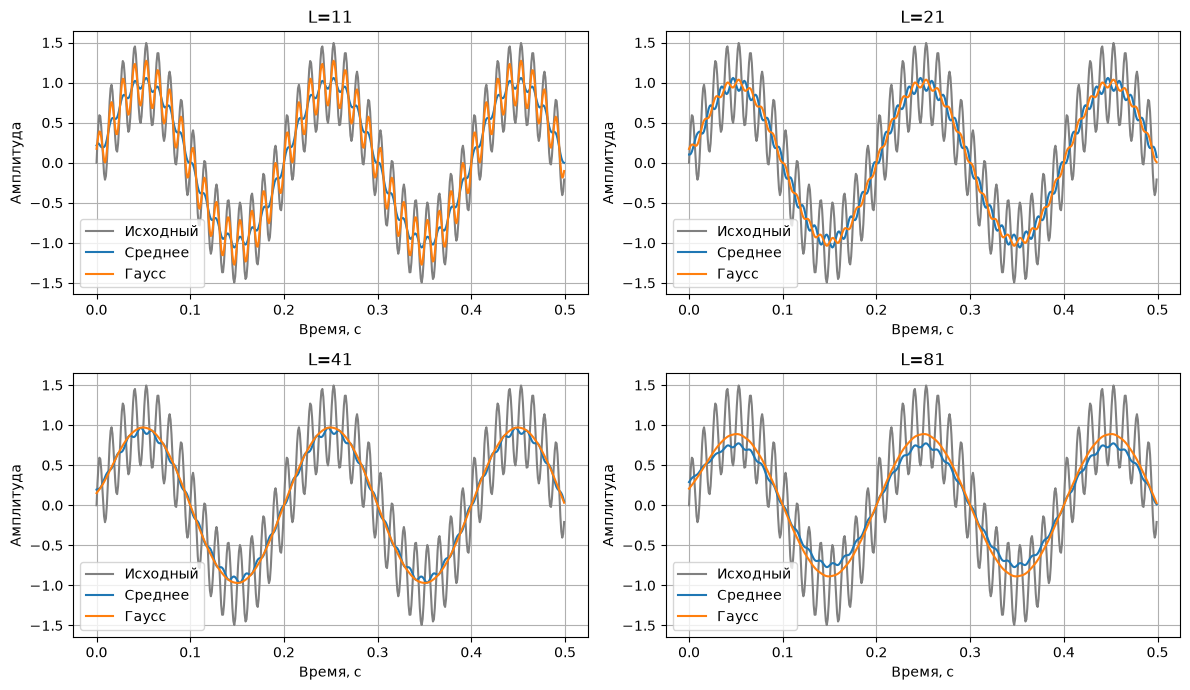

In [3]:
fs = 1000
t = np.arange(2*fs)/fs
x = np.sin(2*np.pi*5*t) + 0.5*np.sin(2*np.pi*80*t)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
print('Окно, длина, амплитуды 5 и 80 Гц:')
for ax, L in zip(axes.flat, [11, 21, 41, 81]):
    ax.plot(t[:500], x[:500], color='gray', label='Исходный')
    for name, w in [('Среднее', np.ones(L)), ('Гаусс', signal.windows.gaussian(L, L/5))]:
        y = np.convolve(x, w/w.sum(), mode='same')
        amp = 2*abs(np.fft.rfft(y))/len(y)
        print(name, L, round(amp[10], 4), round(amp[160], 4))
        ax.plot(t[:500], y[:500], label=name)
    ax.set(title=f'L={L}', xlabel='Время, с', ylabel='Амплитуда')
    ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:**
- Какое окно (прямоугольное или гауссовское) даёт лучшее подавление высокой частоты при одинаковой длине?
- При какой длине прямоугольного и гауссовского окон амплитуда высокочастотного амплитуда падает в 10 раз?
- Как увеличение длины окна влияет на подавление сохранение амплитуды низкой частоты? При какой длине окон она уменьшается более чем на 10%?

При L=11 у меня прямоугольное окно сильнее подавило 80 Гц, а при остальных длинах — гауссово. У прямоугольного результат зависит от близости частоты к нулю АЧХ, поэтому одного лучшего окна тут нет.

В 10 раз амплитуда 80 Гц упала при L=41 и 81 у обоих окон. У гауссова L=21 почти хватило: осталось около 0,0502 при границе 0,05. Полезные 5 Гц потеряли больше 10% при L=81: у среднего осталось 0,754, у гауссова — 0,889.

## Задание 3. Поиск временной задержки с помощью кросс-корреляции

### Цель
Определить временной сдвиг между двумя сигналами в присутствии шума и оценить влияние уровня шума на точность.

### Задание
1. Сгенерируйте сигнал длительностью 1 секунду (fs=1000 Гц), представляющий собой сумму 100 синусоид со случайными частотами (в диапазоне 10–100 Гц), амплитудами (в диапазоне 0.5–1.5 Гц) и фазами (в диапазоне 0–2$\pi$). Воспользуйтесь функцией `numpy.random.uniform`. Нормализуйте полученный сигнал в интервале $[-1;1]$. Назовём его `x`.
2. Создайте второй сигнал `y`, который является сдвинутой во времени копией `x` на `delay` отсчётов (выберите задержку, например, 100 отсчётов) и добавьте к нему случайный сигнал (шум) с уровнем `noise_level` (например, 0.1) с помощью функции `numpy.random.randn`.
3. Вычислите кросс-корреляцию `corr = np.correlate(x, y, mode='full')` и найдите индекс максимума. Оцените задержку как `delay_est = argmax(corr) - (len(x)-1)` (поскольку `mode='full'` даёт диапазон от -N+1 до N-1).
4. Повторите эксперимент для различных уровней шума в диапазоне от `0` до `2`.
5. Для двух уровней шума (0.3 и 2) постройте график кросс-корреляции и отметьте положение истинной и найденной задержки.

Шум: 0 задержка: 100 ошибка: 0
Шум: 0.1 задержка: 100 ошибка: 0
Шум: 0.3 задержка: 100 ошибка: 0
Шум: 0.5 задержка: 100 ошибка: 0
Шум: 1 задержка: 100 ошибка: 0
Шум: 2 задержка: 101 ошибка: 1


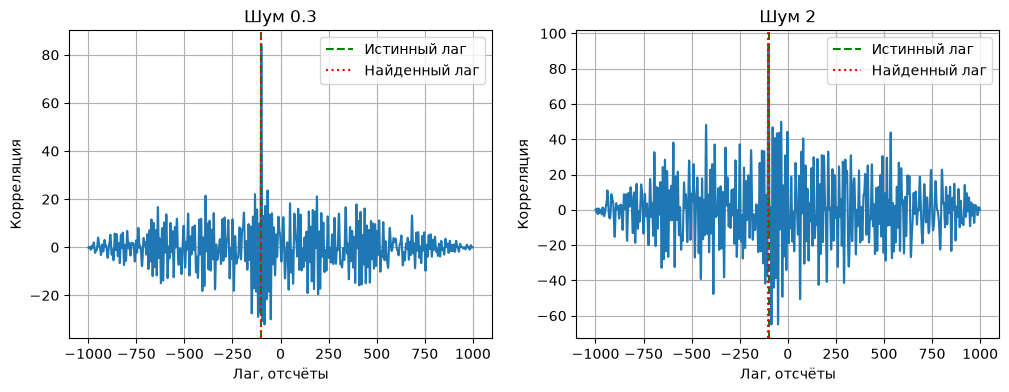

In [4]:
fs = 1000
t = np.arange(fs)/fs
x = np.zeros(fs)
for _ in range(100):
    f = rng.uniform(10, 100)
    x += rng.uniform(0.5, 1.5)*np.sin(2*np.pi*f*t + rng.uniform(0, 2*np.pi))
x /= np.max(abs(x))
delay = 100
y_clean = np.r_[np.zeros(delay), x[:-delay]]
lags = signal.correlation_lags(len(x), len(x))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sigma in [0, 0.1, 0.3, 0.5, 1, 2]:
    y = y_clean + sigma*rng.standard_normal(len(x))
    corr = np.correlate(x, y, mode='full')
    lag = lags[np.argmax(corr)]
    print('Шум:', sigma, 'задержка:', -lag, 'ошибка:', abs(-lag-delay))
    if sigma in [0.3, 2]:
        ax = axes[0 if sigma == 0.3 else 1]
        ax.plot(lags, corr)
        ax.axvline(-delay, color='g', ls='--', label='Истинный лаг')
        ax.axvline(lag, color='r', ls=':', label='Найденный лаг')
        ax.set(title=f'Шум {sigma}', xlabel='Лаг, отсчёты', ylabel='Корреляция')
        ax.legend()
plt.show()

**Вопросы:**
- Как зависит точность оценки задержки от уровня шума? При каком уровне шума вычисленная задержка отличается от истинной более чем на 10%? При каком уровне шума вычисленная задержка становится практически неотличима от `0`?
- Почему при высоком уровне шума могут появляться ложные пики?

Без шума задержка 100 отсчётов. В этих отдельных опытах шум до 2 тоже не дал ошибки больше 10 отсчётов. Значит, резкого ухудшения на проверенных уровнях у меня не получилось; для точного порога нужны дополнительные прогоны. При этом знак надо учитывать: у `correlate(x, y)` задержанному y соответствует отрицательный лаг.

## Задание 4. Обнаружение шаблона в зашумлённом сигнале

### Цель
Найти местоположение сигнала, имеющего форму гауссова импульса, модулированного синусоидой, в смеси с шумом. Исследовать влияние отношения сигнал/шум на точность обнаружения.

### Задание
1. Создайте шаблон `template` – произведение гауссовой огибающей (σ=100 отсчётов) на синусоиду частотой 20 Гц (при fs=1000 Гц). Длина шаблона примерно 6σ.
2. Создайте длинный сигнал `long_signal` длиной 2000 отсчётов, состоящий из:
   - случайного сигнала (шума), созданного с помощью `numpy.random.randn()` с единичной амплитудой,
   - вставленного в случайную позицию шаблона, умноженного на амплитуду `A` (например, 2).
3. Используйте кросс-корреляцию `np.correlate(long_signal, template, mode='valid')` для поиска позиции шаблона. Найдите индекс максимума корреляции.
4. Повторите эксперимент для разных отношений сигнал/шум (SNR), варьируя амплитуду шаблона от 0.2 до 5.
5. Для одного значения SNR (например, 1) визуализируйте: исходный длинный сигнал, шаблон, результат кросс-корреляции с отмеченным пиком.
6. Корреляция с шаблоном – это **согласованный фильтр**. Разделите результат корреляции на $\sqrt{E_s}$, где $E_s = \sum s^2[n]$ – энергия шаблона: тогда шум на выходе имеет единичную дисперсию. Сравните высоту пика с теоретическим значением $A\sqrt{E_s}$.
7. Замените шаблон гауссовым импульсом **без** модуляции с той же энергией и повторите п. 4. Изменилась ли надёжность обнаружения?

С синусом A= 0.2 SNR= -22.3 ошибка позиции: 56 пик: 2.76 теория: 1.88
Без синуса A= 0.2 SNR= -22.3 ошибка позиции: 53 пик: 1.83 теория: 1.88
С синусом A= 0.5 SNR= -14.3 ошибка позиции: 53 пик: 4.96 теория: 4.71
Без синуса A= 0.5 SNR= -14.3 ошибка позиции: 33 пик: 4.53 теория: 4.71
С синусом A= 1 SNR= -8.3 ошибка позиции: 2 пик: 9.36 теория: 9.41
Без синуса A= 1 SNR= -8.3 ошибка позиции: 22 пик: 9.16 теория: 9.41
С синусом A= 2 SNR= -2.3 ошибка позиции: 1 пик: 18.66 теория: 18.83
Без синуса A= 2 SNR= -2.3 ошибка позиции: 12 пик: 18.51 теория: 18.83
С синусом A= 5 SNR= 5.7 ошибка позиции: 0 пик: 46.79 теория: 47.07
Без синуса A= 5 SNR= 5.7 ошибка позиции: 4 пик: 46.72 теория: 47.07


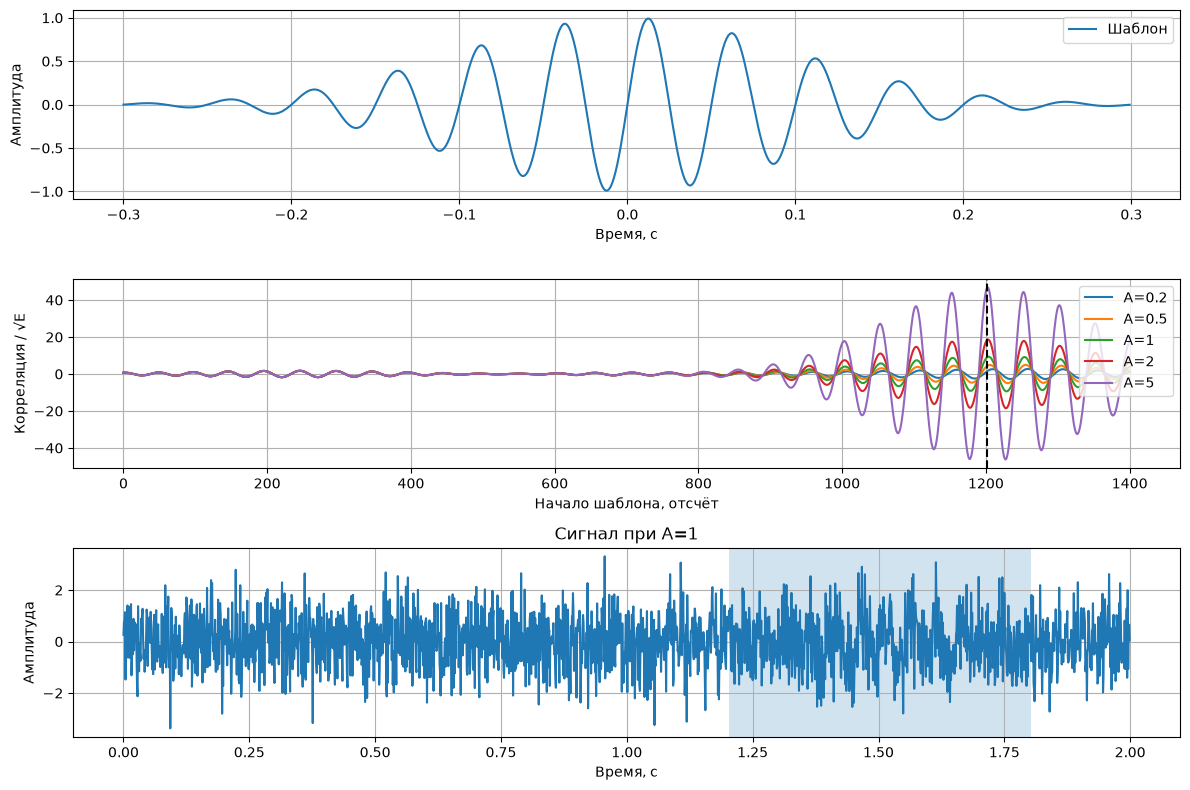

In [5]:
fs = 1000
n = np.arange(-300, 300)
gauss = np.exp(-n**2/(2*100**2))
template = gauss*np.sin(2*np.pi*20*n/fs)
energy = np.sum(template**2)
plain = gauss*np.sqrt(energy/np.sum(gauss**2))
position = int(rng.integers(0, 1401))
noise = rng.standard_normal(2000)
fig, axes = plt.subplots(3, 1, figsize=(12, 8))
axes[0].plot(n/fs, template, label='Шаблон')
for A in [0.2, 0.5, 1, 2, 5]:
    for name, temp in [('С синусом', template), ('Без синуса', plain)]:
        x = noise.copy()
        x[position:position+len(temp)] += A*temp
        corr = np.correlate(x, temp, mode='valid')/np.sqrt(energy)
        found = np.argmax(corr)
        snr_db = 10*np.log10(A**2*energy/len(temp))
        print(name, 'A=', A, 'SNR=', round(snr_db, 1),
              'ошибка позиции:', abs(found-position),
              'пик:', round(corr.max(), 2), 'теория:', round(A*np.sqrt(energy), 2))
        if name == 'С синусом':
            axes[1].plot(corr, label=f'A={A}')
            if A == 1:
                axes[2].plot(np.arange(len(x))/fs, x)
                axes[2].axvspan(position/fs, (position+len(temp))/fs, alpha=0.2)
axes[0].set(xlabel='Время, с', ylabel='Амплитуда')
axes[1].axvline(position, color='k', ls='--')
axes[1].set(xlabel='Начало шаблона, отсчёт', ylabel='Корреляция / √E')
axes[2].set(title='Сигнал при A=1', xlabel='Время, с', ylabel='Амплитуда')
for ax in axes[:2]:
    ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:**
- При каком SNR результаты измерения резко ухудшаются?
- Совпадает ли высота пика нормированной корреляции с теоретической $A\sqrt{E_s}$? Почему надёжность обнаружения определяется энергией шаблона, а не его формой?

На малых A=0,2–0,5 ошибка позиции шаблона с синусом около 53 отсчётов: максимум перескакивает на соседние колебания. Это SNR примерно от −22 до −14 дБ. При A=1, то есть около −8 дБ, ошибка два отсчёта. У чистого гаусса максимум шире, и позиция уточняется медленнее.

Высота полезного отклика получается A·√Es. При равной энергии высота отклика сопоставима, а точность позиции зависит ещё и от формы автокорреляции.

## Задание 5. Поиск фрагмента в реальном аудиосигнале

### Цель
Применить кросс-корреляцию для нахождения заданного фрагмента в аудиофайле. Фрагмент и основной файл предоставлены (студентам нужно будет загрузить их).

### Задание
1. Загрузите аудиофайл `full_audio.wav` и фрагмент `fragment.wav`. Используйте `scipy.io.wavfile.read`.
2. Вычислите кросс-корреляцию между полным сигналом и фрагментом.
3. Найдите позицию максимального значения корреляции и определите временное смещение (в отсчётах и в секундах).
4. Постройте график кросс-корреляции и отметьте найденный пик.
5. Вырежьте из полного сигнала участок, соответствующий найденной позиции, и прослушайте его (используйте `Audio`). Убедитесь, что он совпадает с фрагментом.
6. Вычислите **нормированную** корреляцию: разделите результат на $\sqrt{E_s \cdot E_x[m]}$, где $E_x[m]$ – энергия участка полного сигнала, с которым сравнивается фрагмент при сдвиге $m$ (см. заметки к занятию). Сравните графики нормированной и ненормированной корреляции.

In [6]:
full_path = data_dir / 'full_audio.wav'
fragment_path = data_dir / 'fragment.wav'

Обычная корреляция:

C:\Users\n1\AppData\Local\Temp\ipykernel_20688\122606262.py:1: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs_full, full = wavfile.read(full_path)
C:\Users\n1\AppData\Local\Temp\ipykernel_20688\122606262.py:2: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs_fragment, fragment = wavfile.read(fragment_path)


 6.331859410430839 с
Нашёл фрагмент: 279235 отсчётов, 6.331859 с
Коэффициент: 1.0


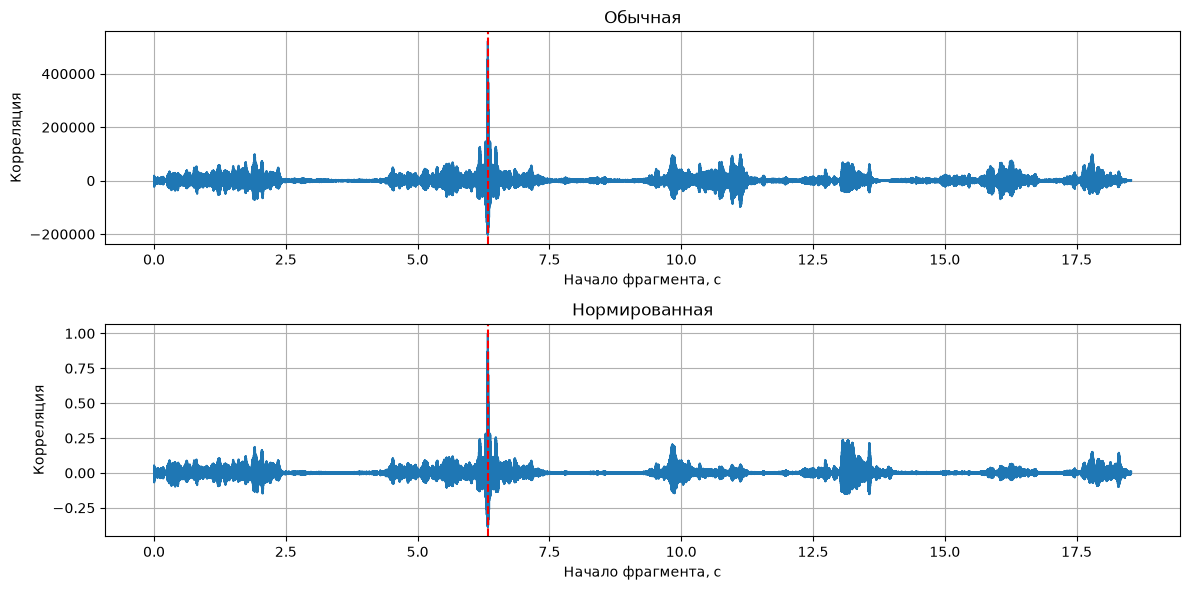

In [7]:
fs_full, full = wavfile.read(full_path)
fs_fragment, fragment = wavfile.read(fragment_path)
full = full.astype(float).mean(axis=1)
fragment = fragment.mean(axis=1)
full -= full.mean()
fragment -= fragment.mean()
M = len(fragment)
corr = signal.correlate(full, fragment, mode='valid', method='fft')
energy = np.r_[0, np.cumsum(full**2)]
section_energy = energy[M:] - energy[:-M]
normalized = corr / np.sqrt(np.sum(fragment**2)*np.maximum(section_energy, 1e-12))
position = np.argmax(normalized)
print('Обычная корреляция:', np.argmax(corr)/fs_full, 'с')
print('Нашёл фрагмент:', position, 'отсчётов,', round(position/fs_full, 6), 'с')
print('Коэффициент:', round(normalized[position], 4))
times = np.arange(len(corr))/fs_full
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, values, name in zip(axes, [corr, normalized], ['Обычная', 'Нормированная']):
    ax.plot(times, values)
    ax.axvline(position/fs_full, color='r', ls='--')
    ax.set(title=name, xlabel='Начало фрагмента, с', ylabel='Корреляция')
plt.tight_layout()
plt.show()
display(Audio(fragment, rate=fs_fragment))
display(Audio(full[position:position+M], rate=fs_full))

**Вопросы:**
- Почему перед вычислением корреляции сигналы следует нормализовать? Какие ложные максимумы исчезают после нормировки на энергию текущего участка?
- Сколько раз в сигнале встречается вырезанное во фрагменте слово? Удаётся ли с помощью корреляционного анализа определить его во всех случаях? Возникают ли ложные максимумы?
- Что будет, если фрагмент не содержится в полном сигнале? Как это отразится на корреляции?

точная копия нашлась примерно на 6,33с, коэффициент 1. Нормировка на энергию каждого участка нужна, чтобы просто громкое место не выигрывало у похожего.

По этому графику можно сказать про одну точную копию. Все повторения слова так посчитать сложнее: темп и интонация меняются, а небольшой пик может быть случайным.

## Задание 6. Z-преобразование: передаточная функция, полюса и нули

### Цель
Научиться находить передаточную функцию по разностному уравнению, определять устойчивость системы по расположению полюсов и связывать полюса и нули с видом АЧХ.

### Задание
Рассмотрите системы (частота дискретизации $f_s = 1000$ Гц):
- (а) $y[n] = x[n] + 0.8\,y[n-1]$;
- (б) $y[n] = x[n] - 1.1\,y[n-1]$;
- (в) $y[n] = x[n] - x[n-2]$;
- (г) резонатор $y[n] = x[n] + 2r\cos\theta\;y[n-1] - r^2\,y[n-2]$ с $r = 0.95$, $\theta = \pi/5$.

1. Запишите (в ячейке ответа) передаточные функции $H(z)$ и найдите вручную их полюса и нули.
2. Задайте коэффициенты `b`, `a` и найдите полюса и нули с помощью `signal.tf2zpk(b, a)`. Сравните с ручным расчётом. Изобразите их на комплексной плоскости вместе с единичной окружностью (функция `zplane` ниже).
3. Вычислите импульсные характеристики (50 отсчётов, `signal.lfilter`). Какие системы устойчивы? Согласуется ли это с положением полюсов?
4. Для устойчивых систем постройте АЧХ (`signal.freqz(b, a, fs=1000)`). Объясните положение максимумов и провалов АЧХ через положение полюсов и нулей.
5. Для резонатора постройте импульсные характеристики и АЧХ при $r = 0.5,\ 0.9,\ 0.99$. Как ширина резонансного пика и скорость затухания связаны с расстоянием от полюса до единичной окружности?
6. Проверьте теорему о свёртке для Z-преобразования: возьмите два КИХ-фильтра, например `b1 = [1, 1]` и `b2 = [1, -2, 1]`. Убедитесь, что `np.convolve(b1, b2)` совпадает с `np.polymul(b1, b2)`, а АЧХ каскада равна произведению АЧХ отдельных фильтров.

(а) нули [0.], полюса [0.8], устойчива: True


(б) нули [0.], полюса [-1.1], устойчива: False
(в) нули [-1.  1.], полюса [0. 0.], устойчива: True
(г) нули [0. 0.], полюса [0.76856614+0.55839599j 0.76856614-0.55839599j], устойчива: True


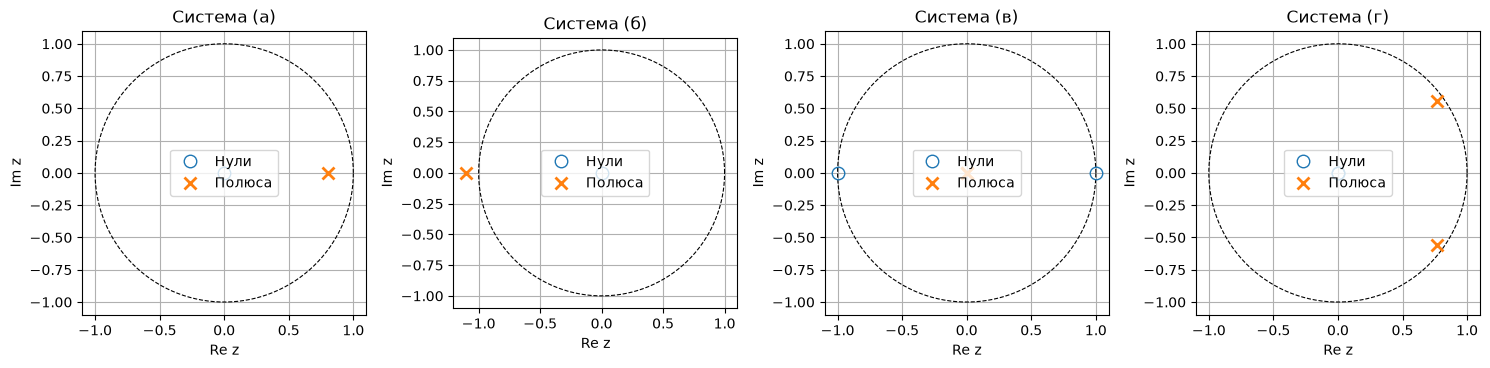

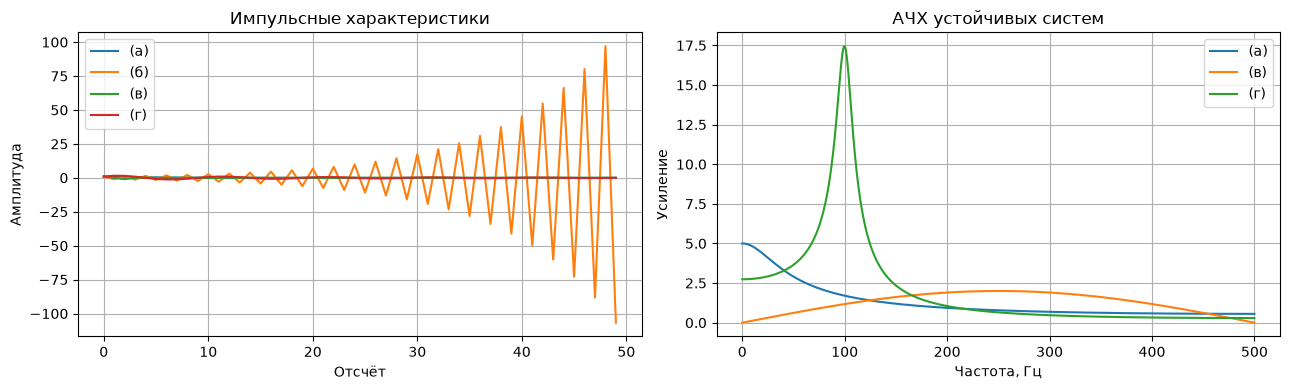

Резонатор r=0.5: максимум на 0.000 Гц
Резонатор r=0.9: максимум на 98.785 Гц
Резонатор r=0.99: максимум на 99.976 Гц


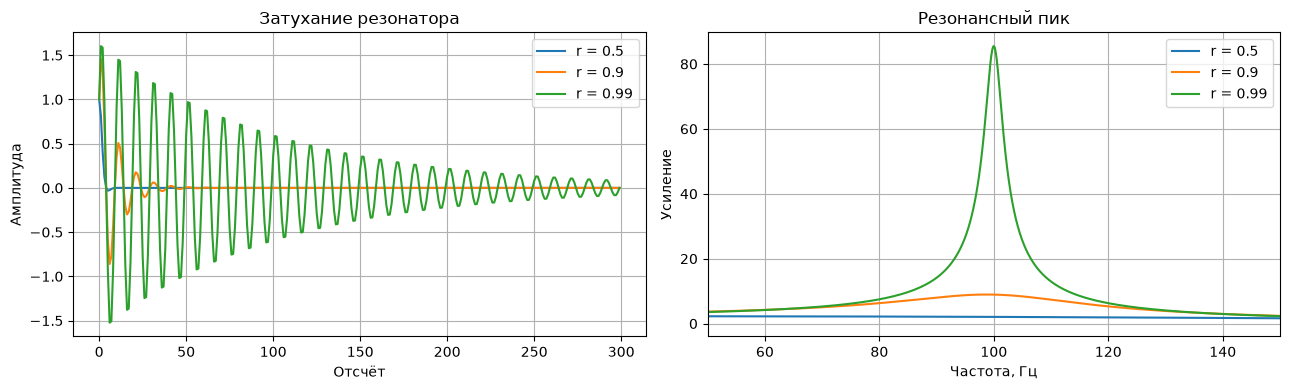

Свёртка: [ 1 -1 -1  1] ; произведение полиномов: [ 1 -1 -1  1]
Максимальная ошибка Hкаскада − H1·H2: 1.1620938331323894e-15


In [8]:
def zplane(b, a, ax, title):
    length = max(len(b), len(a))
    bp = list(b) + [0]*(length-len(b))
    ap = list(a) + [0]*(length-len(a))
    zeros, poles, gain = signal.tf2zpk(bp, ap)
    circle = np.exp(1j*np.linspace(0, 2*np.pi, 400))
    ax.plot(circle.real, circle.imag, 'k--', lw=.8)
    ax.plot(zeros.real, zeros.imag, 'o', mfc='none', ms=9, label='Нули')
    ax.plot(poles.real, poles.imag, 'x', ms=9, mew=2, label='Полюса')
    ax.set(title=title, xlabel='Re z', ylabel='Im z', aspect='equal')
    ax.legend()
    return zeros, poles

fs = 1000
r, theta = .95, np.pi/5
systems = {'а': ([1], [1, -.8]),
           'б': ([1], [1, 1.1]),
           'в': ([1, 0, -1], [1]),
           'г': ([1], [1, -2*r*np.cos(theta), r*r])}
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, (b, a)) in zip(axes, systems.items()):
    zeros, poles = zplane(b, a, ax, f'Система ({name})')
    print(f'({name}) нули {zeros}, полюса {poles}, устойчива: {np.all(abs(poles)<1)}')
plt.tight_layout()
plt.show()

impulse = np.r_[1., np.zeros(49)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (b, a) in systems.items():
    axes[0].plot(signal.lfilter(b, a, impulse), label=f'({name})')
    if name != 'б':
        f, H = signal.freqz(b, a, worN=8192, fs=fs)
        axes[1].plot(f, abs(H), label=f'({name})')
axes[0].set(title='Импульсные характеристики', xlabel='Отсчёт', ylabel='Амплитуда')
axes[1].set(title='АЧХ устойчивых систем', xlabel='Частота, Гц', ylabel='Усиление')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for r in (.5, .9, .99):
    a = [1, -2*r*np.cos(theta), r*r]
    axes[0].plot(signal.lfilter([1], a, np.r_[1., np.zeros(299)]), label=f'r = {r}')
    f, H = signal.freqz([1], a, worN=16384, fs=fs)
    axes[1].plot(f, abs(H), label=f'r = {r}')
    print(f'Резонатор r={r}: максимум на {f[np.argmax(abs(H))]:.3f} Гц')
axes[0].set(title='Затухание резонатора', xlabel='Отсчёт', ylabel='Амплитуда')
axes[1].set(title='Резонансный пик', xlabel='Частота, Гц', ylabel='Усиление', xlim=(50, 150))
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

b1, b2 = [1, 1], [1, -2, 1]
b_cascade = np.convolve(b1, b2)
print('Свёртка:', b_cascade, '; произведение полиномов:', np.polymul(b1, b2))
f, H1 = signal.freqz(b1, [1], fs=fs)
_, H2 = signal.freqz(b2, [1], fs=fs)
_, Hcascade = signal.freqz(b_cascade, [1], fs=fs)
print('Максимальная ошибка Hкаскада − H1·H2:', np.max(abs(Hcascade-H1*H2)))

**Вопросы:**
- Какие из систем (а)–(г) устойчивы? Сформулируйте условие устойчивости через полюса.
- Почему система (в) пропускает средние частоты и не пропускает постоянную составляющую и частоту $f_s/2$?
- Как угол полюса резонатора $\theta$ связан с частотой максимума АЧХ? Чему равна эта частота при $f_s = 1000$ Гц?

передаточные функции:

- (а) $H(z)=z/(z-0.8)$: нуль 0, полюс 0.8.
- (б) $H(z)=z/(z+1.1)$: нуль 0, полюс −1.1.
- (в) $H(z)=(z^2-1)/z^2$: нули ±1, два полюса 0.
- (г) $H(z)=z^2/(z^2-2r\cos\theta\,z+r^2)$: два нуля 0, полюса $re^{\pm j\theta}$.

У причинной системы все полюса должны быть внутри единичной окружности. Значит, (а), (в) и (г) устойчивы, а (б) разгоняется. У (в) нули на 0 и 500 Гц, максимум на 250 Гц

угол задаёт частоту колебаний $\theta f_s/(2\pi)=100$ Гц. Чем ближе r к 1, тем уже пик и дольше затухание. При маленьком r максимум АЧХ может заметно отличаться от 100 Гц. Ну и свёртка `[1, -1, -1, 1]` совпала с произведением полиномов, как ожидалось.

## Общий вывод

Свёрткой я сглаживал сигнал, а корреляцией искал задержку и знакомый фрагмент. На аудио точная копия нашлась хорошо, но все повторения слова одним максимумом уже не определить. В общем, нормировка и знак задержки тут легко могут испортить ответ, если их не проверить.